# Hybrid Modelling & Optimization: Fast-Charging an EV Battery Cell

**Case Study 5.** Physics model + ML residual correction + constrained optimization.

Flow of this notebook (matches the 25 min Colab slot):
1. Load the data
2. Physics-only baseline
3. ML-only baseline
4. Hybrid model (physics + ML correction)
5. Compare, including on charge rates the models never saw
6. Optimize the charging profile under constraints
7. Results and limitations

The data is synthetic. Cell size, 2 Ah capacity and the 30% fade end-of-life follow the public NASA Ames PCoE Li-ion 18650 aging dataset.

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.optimize import differential_evolution
from scipy.interpolate import RegularGridInterpolator

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3})
np.random.seed(0)

Upload `ev_cell_charging_data.xlsx` when prompted (in Colab). If the file is already next to the notebook it is used directly.

In [2]:
FILE = "ev_cell_charging_data.xlsx"
if not os.path.exists(FILE):
    from google.colab import files
    files.upload()          # pick ev_cell_charging_data.xlsx

## 1. Data: inputs and outputs

In [3]:
params = pd.read_excel(FILE, sheet_name="Parameters", nrows=10)
P = dict(zip(params["Parameter"], params["Value"]))
Q0   = P["Q0 (nominal capacity)"]            # Ah
VMAX = P["V_max (charge limit)"]             # V
R0   = P["R0 (physics model resistance)"]    # ohm
CTH  = P["C_th (thermal mass)"]              # J/K
HA   = P["hA (heat loss coefficient)"]       # W/K
TMAX = P["T_max (safe cell temperature)"]    # C

ocv_tab = pd.read_excel(FILE, sheet_name="OCV_Table")
def ocv(soc):
    return np.interp(soc, ocv_tab["SOC"], ocv_tab["OCV_V"])

train = pd.read_excel(FILE, sheet_name="Train_Data")
test_ex = pd.read_excel(FILE, sheet_name="Test_Extrapolation")

IN_ALL  = ["C_rate", "SOC", "T_amb_C", "T_cell_C", "Cycle_count"]   # inputs for ML-only
OUT_V, OUT_T = "V_term_V", "dTdt_K_per_min"                          # outputs

print(train.shape, test_ex.shape)
print("Train C-rate range:      ", train.C_rate.min().round(2), "to", train.C_rate.max().round(2))
print("Extrapolation C-rate:    ", test_ex.C_rate.min().round(2), "to", test_ex.C_rate.max().round(2))
train.head()

(2000, 10) (500, 10)
Train C-rate range:       0.2 to 1.5
Extrapolation C-rate:     2.0 to 3.0


,Sample_ID,C_rate,SOC,T_amb_C,T_cell_C,Cycle_count,V_term_V,dTdt_K_per_min,Current_A,Q_phys_W
0,TR0001,1.2061,0.7663,22.90,29.73,598,4.2254,-0.1580,2.4122,0.407310
1,TR0002,0.7705,0.4294,13.93,15.71,336,3.9385,0.1285,1.5410,0.166228
2,TR0003,1.3162,0.8600,26.30,34.83,23,4.2179,-0.6558,2.6324,0.485067
3,TR0004,1.1066,0.6032,11.02,13.37,539,4.2058,0.6695,2.2132,0.342878
4,TR0005,0.3224,0.1485,18.46,19.37,571,3.6263,0.0309,0.6448,0.029104


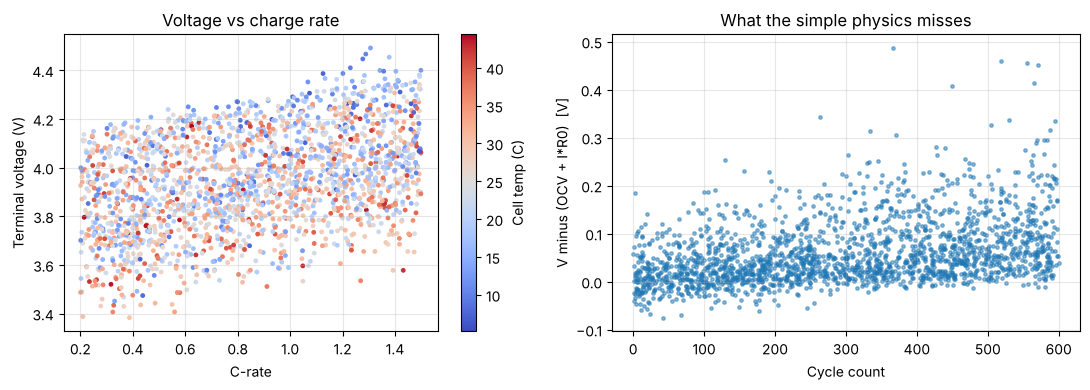

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
s = ax[0].scatter(train.C_rate, train[OUT_V], c=train.T_cell_C, s=6, cmap="coolwarm")
ax[0].set(xlabel="C-rate", ylabel="Terminal voltage (V)", title="Voltage vs charge rate")
plt.colorbar(s, ax=ax[0], label="Cell temp (C)")
ax[1].scatter(train.Cycle_count, train[OUT_V] - ocv(train.SOC) - train.C_rate * Q0 * R0, s=6, alpha=0.5)
ax[1].set(xlabel="Cycle count", ylabel="V minus (OCV + I*R0)  [V]", title="What the simple physics misses")
plt.tight_layout(); plt.show()

## 2. Physics-only model

Equivalent circuit (simplified): open-circuit voltage plus a constant series resistance, and a lumped thermal balance.

- Voltage: `V = OCV(SOC) + I * R0`
- Heating: `dT/dt = (I^2 * R0 - hA * (T_cell - T_amb)) / C_th`

Clean and explainable, but R0 is a single datasheet number.

In [5]:
def physics_predict(df, R=R0):
    I = df.C_rate * Q0
    R = np.broadcast_to(R, len(df))
    V = ocv(df.SOC) + I * R
    dTdt = (I**2 * R - HA * (df.T_cell_C - df.T_amb_C)) / CTH * 60
    return V.values, dTdt.values

def rmse(a, b): return np.sqrt(mean_squared_error(a, b))

# in-range hold-out for fair "inside the training range" scores
tr, te = train_test_split(train, test_size=0.2, random_state=1)

results = {}
for name, df in [("In range", te), ("Extrapolation (2-3 C)", test_ex)]:
    v, d = physics_predict(df)
    results[("Physics only", name)] = (rmse(df[OUT_V], v) * 1000, mean_absolute_error(df[OUT_T], d))
results

{('Physics only', 'In range'): (np.float64(88.3076599385353),
  0.17485732782266666),
 ('Physics only', 'Extrapolation (2-3 C)'): (np.float64(177.6047823192157),
  0.9107239387039998)}

## 3. ML-only model

Gradient boosting on all five inputs, predicting voltage and heating rate directly. No physics inside.

In [6]:
ml_v = GradientBoostingRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, random_state=0).fit(tr[IN_ALL], tr[OUT_V])
ml_t = GradientBoostingRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, random_state=0).fit(tr[IN_ALL], tr[OUT_T])

for name, df in [("In range", te), ("Extrapolation (2-3 C)", test_ex)]:
    v, d = ml_v.predict(df[IN_ALL]), ml_t.predict(df[IN_ALL])
    results[("ML only", name)] = (rmse(df[OUT_V], v) * 1000, mean_absolute_error(df[OUT_T], d))
{k: v for k, v in results.items() if k[0] == "ML only"}

{('ML only', 'In range'): (np.float64(15.682622350775155),
  0.07142004457695525),
 ('ML only', 'Extrapolation (2-3 C)'): (np.float64(192.39953981473673),
  1.794975273745405)}

## 4. Hybrid model: physics + ML correction

Key idea: do not ask ML to learn voltage from scratch. Keep the physics equations and let ML correct the one thing physics gets wrong, the **effective resistance**.

1. From each measurement compute the observed extra resistance: `dR = (V - OCV) / I - R0`
2. Train ML to predict `dR` from the inputs that physically drive resistance: **SOC, cell temperature, cycle count**
3. Plug `R = R0 + dR_ML` back into the **same** voltage and heating equations

One correction fixes both outputs, and because current stays inside the physics equations, the model keeps working at charge rates it never saw.

In [7]:
FEAT_R = ["SOC", "T_cell_C", "Cycle_count"]

def observed_dR(df):
    I = df.C_rate * Q0
    return (df[OUT_V] - ocv(df.SOC)) / I - R0

dr_model = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=0)
dr_model.fit(tr[FEAT_R], observed_dR(tr))

def hybrid_predict(df):
    R = R0 + dr_model.predict(df[FEAT_R])
    return physics_predict(df, R)

for name, df in [("In range", te), ("Extrapolation (2-3 C)", test_ex)]:
    v, d = hybrid_predict(df)
    results[("Hybrid", name)] = (rmse(df[OUT_V], v) * 1000, mean_absolute_error(df[OUT_T], d))

## 5. Comparison

Voltage RMSE (mV)  \
Model        Test set                                   
Physics only In range                          88.308   
             Extrapolation (2-3 C)            177.605   
ML only      In range                          15.683   
             Extrapolation (2-3 C)            192.400   
Hybrid       In range                           6.645   
             Extrapolation (2-3 C)             39.006   

                                    Heating-rate MAE (K/min)  
Model        Test set                                         
Physics only In range                                  0.175  
             Extrapolation (2-3 C)                     0.911  
ML only      In range                                  0.071  
             Extrapolation (2-3 C)                     1.795  
Hybrid       In range                                  0.029  
             Extrapolation (2-3 C)                     0.239

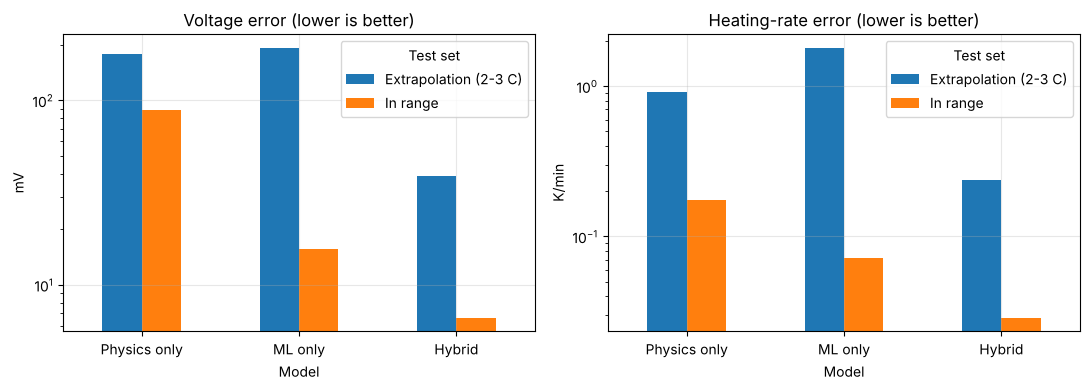

In [8]:
tab = pd.DataFrame(results, index=["Voltage RMSE (mV)", "Heating-rate MAE (K/min)"]).T
tab.index.names = ["Model", "Test set"]
display(tab.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tab["Voltage RMSE (mV)"].unstack().loc[["Physics only", "ML only", "Hybrid"]].plot.bar(ax=ax[0], rot=0)
ax[0].set(title="Voltage error (lower is better)", ylabel="mV"); ax[0].set_yscale("log")
tab["Heating-rate MAE (K/min)"].unstack().loc[["Physics only", "ML only", "Hybrid"]].plot.bar(ax=ax[1], rot=0)
ax[1].set(title="Heating-rate error (lower is better)", ylabel="K/min"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

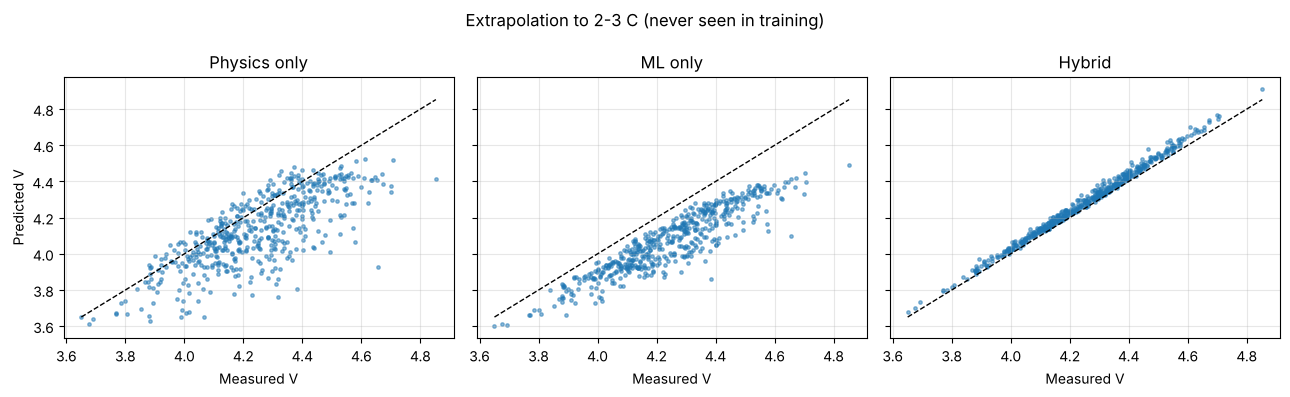

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
preds = {"Physics only": physics_predict(test_ex)[0],
         "ML only": ml_v.predict(test_ex[IN_ALL]),
         "Hybrid": hybrid_predict(test_ex)[0]}
lo, hi = test_ex[OUT_V].min(), test_ex[OUT_V].max()
for a, (n, p) in zip(ax, preds.items()):
    a.scatter(test_ex[OUT_V], p, s=6, alpha=0.5)
    a.plot([lo, hi], [lo, hi], "k--", lw=1)
    a.set(title=n, xlabel="Measured V")
ax[0].set_ylabel("Predicted V")
fig.suptitle("Extrapolation to 2-3 C (never seen in training)")
plt.tight_layout(); plt.show()

**Reading this:**
- Physics only: right shape, biased, because the real resistance is higher than R0 once the cell is aged or cold.
- ML only: fine inside the training range, but trees cannot extend beyond the data, so it flat-lines at high current.
- Hybrid: small error in range and at 2 to 3 C, because current stays inside the physics.

## 6. Optimization: fastest safe charge

**Decision variables:** charge rate in three SOC bands (10-35%, 35-60%, 60-80%).

**Objective:** minimize charge time from 10% to 80% SOC.

**Constraints:**
- terminal voltage <= V_max
- cell temperature <= T_max
- degradation proxy <= 2x the proxy of a plain 1 C charge (the degradation proxy is `integral of C^2 * exp(0.05*(T-25)) dt`, a simple stress measure: fast and hot is worse)

**Scenario:** aged cell (400 cycles) at 25 C ambient.

We optimize on the physics-only model and on the hybrid model, then **check both answers against the hidden "real cell"** to see which one you can trust.

In [10]:
CYC, T_AMB = 400, 25.0
BANDS = [(0.10, 0.35), (0.35, 0.60), (0.60, 0.80)]
DT = 10.0  # s

# --- fast lookup of the ML resistance correction on a grid (cycle count fixed) ---
soc_g = np.linspace(0.05, 0.9, 40)
t_g = np.linspace(5, 45, 40)
SS, TT = np.meshgrid(soc_g, t_g, indexing="ij")
grid = pd.DataFrame({"SOC": SS.ravel(), "T_cell_C": TT.ravel(), "Cycle_count": CYC})
dR_grid = dr_model.predict(grid[FEAT_R]).reshape(SS.shape)
dR_interp = RegularGridInterpolator((soc_g, t_g), dR_grid, bounds_error=False, fill_value=None)

def R_physics(soc, T, c): return R0
def R_hybrid(soc, T, c):  return R0 + float(dR_interp([[np.clip(soc, 0.05, 0.9), np.clip(T, 5, 45)]])[0])

def simulate(c_rates, R_fn, soc0=0.10, soc1=0.80):
    soc, T, t, deg, vmax, tmax = soc0, T_AMB, 0.0, 0.0, 0.0, T_AMB
    while soc < soc1 and t < 20000:
        band = next(k for k, (a, b) in enumerate(BANDS) if soc < b) if soc < BANDS[-1][1] else len(BANDS) - 1
        c = c_rates[band]; I = c * Q0
        R = R_fn(soc, T, c)
        vmax = max(vmax, float(ocv(soc)) + I * R)
        T += DT * (I**2 * R - HA * (T - T_AMB)) / CTH
        tmax = max(tmax, T)
        deg += DT * c**2 * np.exp(0.05 * (T - 25))
        soc += I * DT / (Q0 * 3600); t += DT
    return dict(time_min=t / 60, vmax=vmax, tmax=tmax, deg=deg)

base_ref = simulate([1.0, 1.0, 1.0], R_physics)       # 1C reference for the degradation cap
DEG_CAP = 2.0 * base_ref["deg"]

def optimize(R_fn, seed=0):
    def obj(x):
        r = simulate(x, R_fn)
        pen = 0.0
        pen += max(0, r["vmax"] - VMAX) * 2000
        pen += max(0, r["tmax"] - TMAX) * 50
        pen += max(0, r["deg"] / DEG_CAP - 1) * 500
        return r["time_min"] + pen
    res = differential_evolution(obj, bounds=[(0.3, 3.0)] * 3, seed=seed, maxiter=40, popsize=12, tol=1e-4, polish=False)
    return res.x

### Hidden real cell (for the demo only)
In real life this check is a lab or vehicle test. Here we use the true resistance behind the synthetic data.

In [11]:
B_ARR, K_AGE, K_SOC, K_C = 2500.0, 0.0010, 0.6, 0.04
def R_true(soc, T, c):
    arr = np.exp(B_ARR * (1 / (T + 273.15) - 1 / 298.15))
    return R0 * arr * (1 + K_AGE * CYC) * (1 + K_SOC * (1 - soc) ** 3) * (1 - K_C * c)

In [12]:
x_phys = optimize(R_physics)
x_hyb  = optimize(R_hybrid)

rows = []
for name, x in [("1C constant (baseline)", [1, 1, 1]), ("Optimized on physics-only", x_phys), ("Optimized on hybrid", x_hyb)]:
    r_real = simulate(x, R_true)
    rows.append({"Profile": name,
                 "C-rates (3 bands)": np.round(x, 2).tolist(),
                 "Time (min) real": round(r_real["time_min"], 1),
                 "Peak V real": round(r_real["vmax"], 3),
                 "Peak T real (C)": round(r_real["tmax"], 1),
                 "Deg vs cap": round(r_real["deg"] / DEG_CAP, 2),
                 "Safe on real cell?": r_real["vmax"] <= VMAX + 0.01 and r_real["tmax"] <= TMAX + 0.5 and r_real["deg"] <= DEG_CAP * 1.02})
res_tab = pd.DataFrame(rows)
display(res_tab)
print(f"Limits: V <= {VMAX} V, T <= {TMAX} C, degradation <= 1.00 of cap (safe check allows 10 mV, 0.5 C, 2% tolerance)")

,Profile,C-rates (3 bands),Time (min) real,Peak V real,Peak T real (C),Deg vs cap,Safe on real cell?
0,1C constant (baseline),"[1, 1, 1]",42.2,4.202,28.8,0.53,True
1,Optimized on physics-only,"[1.76, 1.92, 1.22]",26.2,4.220,35.1,1.08,False
2,Optimized on hybrid,"[1.8, 1.72, 1.04]",28.5,4.200,34.0,0.99,True


Limits: V <= 4.2 V, T <= 35.0 C, degradation <= 1.00 of cap (safe check allows 10 mV, 0.5 C, 2% tolerance)


### Trade-off: charge time vs peak temperature

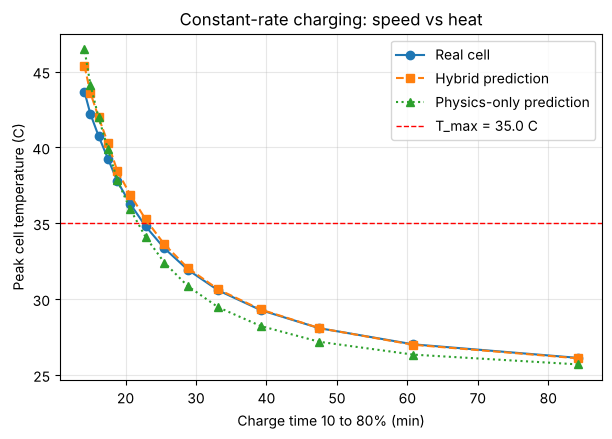

In [13]:
sweep = np.linspace(0.5, 3.0, 14)
pts = []
for c in sweep:
    rr = simulate([c, c, c], R_true)
    rh = simulate([c, c, c], R_hybrid)
    rp = simulate([c, c, c], R_physics)
    pts.append((c, rr["time_min"], rr["tmax"], rh["tmax"], rp["tmax"]))
pts = np.array(pts)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(pts[:, 1], pts[:, 2], "o-", label="Real cell")
ax.plot(pts[:, 1], pts[:, 3], "s--", label="Hybrid prediction")
ax.plot(pts[:, 1], pts[:, 4], "^:", label="Physics-only prediction")
ax.axhline(TMAX, color="r", ls="--", lw=1, label=f"T_max = {TMAX} C")
ax.set(xlabel="Charge time 10 to 80% (min)", ylabel="Peak cell temperature (C)", title="Constant-rate charging: speed vs heat")
ax.legend(); plt.show()

## 7. Results and limitations

**What we achieved**
- Physics alone is biased because one constant resistance cannot capture temperature, SOC and aging.
- ML alone is accurate inside its data but fails at charge rates it never saw.
- The hybrid keeps the physics structure and lets ML correct resistance, so it stays accurate inside and outside the training range.
- An optimizer built on the physics-only model proposes profiles that look fast on paper but break the voltage limit and the degradation cap on the real cell. The hybrid-based optimum respects the limits.

**Limitations (say these out loud)**
- The data is synthetic. The "real cell" is a formula I wrote, so the hybrid has an unfair advantage: the correction has the same shape as the truth.
- ML still cannot extrapolate along cycle count or temperature outside the training range. Hybrid helps for current because current lives in the physics, not for everything.
- The circuit and thermal model are simplified (no RC dynamics, no hysteresis, no gradients inside the cell, no lithium plating).
- The degradation proxy is a stand-in, not a validated aging model.
- The optimum is only as good as the model. Always validate on the real hardware.

**Next steps**
- Replace the synthetic data with the NASA PCoE 18650 charge and discharge cycles.
- Add physics-informed neural networks or a Kalman filter for online resistance tracking.